In [444]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, StandardScaler)

#Subimos el archivo de la carpeta data
set_config(transform_output="pandas")

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

titanic =  pd.read_csv(DATA_DIR/"titanic.csv")
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [445]:
titanic.head(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [446]:
titanic.tail(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [447]:
titanic.info()
titanic.describe()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [448]:
print(titanic.duplicated().mean()*100)
for col in ["survived", "pclass", "age","sibsp","parch","fare","embarked","class","who","adult_male","deck","embark_town","alive","alone"]:
    print(titanic[col].value_counts(dropna=False), "\n")

12.008978675645341
survived
0    549
1    342
Name: count, dtype: int64 

pclass
3    491
1    216
2    184
Name: count, dtype: int64 

age
NaN      177
24.00     30
22.00     27
18.00     26
28.00     25
        ... 
24.50      1
0.67       1
0.42       1
34.50      1
74.00      1
Name: count, Length: 89, dtype: int64 

sibsp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64 

parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64 

fare
8.0500     43
13.0000    42
7.8958     38
7.7500     34
26.0000    31
           ..
13.8583     1
50.4958     1
5.0000      1
9.8458      1
10.5167     1
Name: count, Length: 248, dtype: int64 

embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64 

class
Third     491
First     216
Second    184
Name: count, dtype: int64 

who
man      537
woman    271
child     83
Name: count, dtype: int64 

adult_male
True     537
False    354
Name: count, dtype

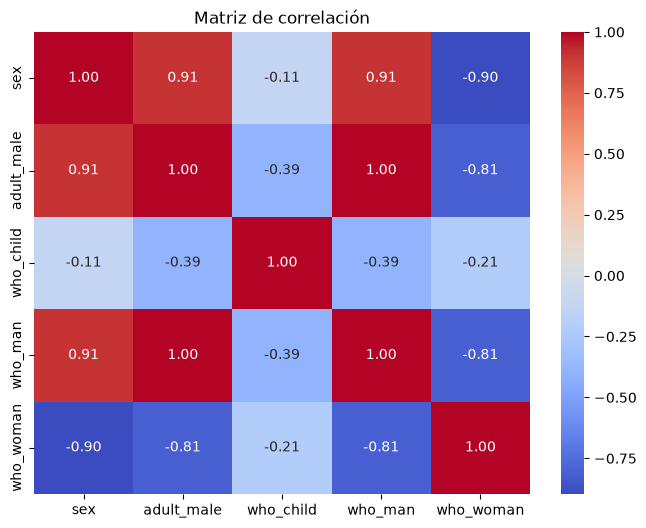

In [449]:
valores = titanic[["sex", "who", "adult_male"]].copy()

valores["sex"] = valores["sex"].map({"male":"1", "female": '0'})

valores["adult_male"] = valores["adult_male"].map({True:"1", False: "0"})

valores = pd.get_dummies(

    valores,

    columns=["who"],

    dtype=int
)

corr = valores.corr()

 

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)

ax.set_title("Matriz de correlación")

plt.show()

## for col in ["survived", "pclass", "age","sibsp","parch","fare","embarked","class","who","adult_male","deck","embark_town","alive","alone"]:

##    print(titanic[col].value_counts(dropna=False), "\n")






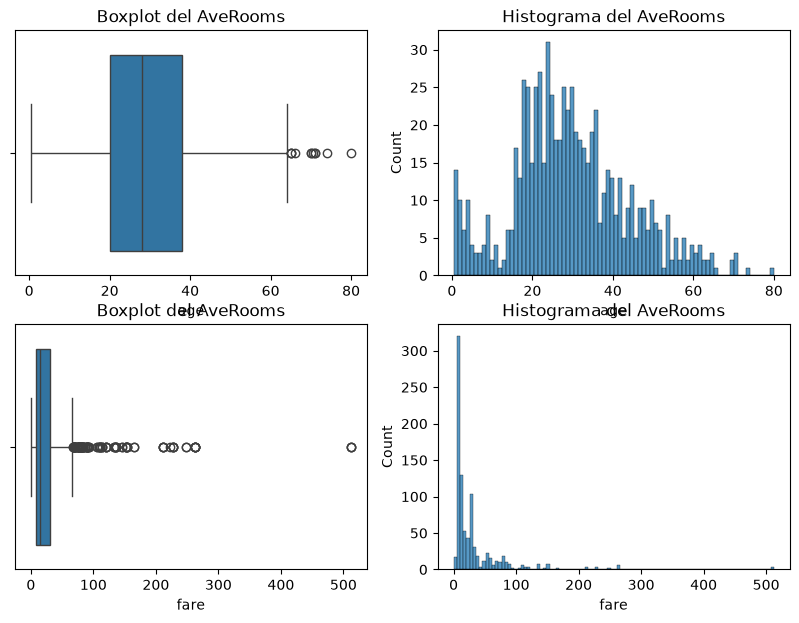

In [450]:


fig1, axes = plt.subplots(2, 2,figsize=(10, 7))
sns.boxplot(x=titanic["age"], ax=axes[0,0])
axes[0,0].set_title("Boxplot del AveRooms")
sns.histplot(x=titanic["age"], bins=80, ax=axes[0,1])
axes[0,1].set_title("Histograma del AveRooms")
sns.boxplot(x=titanic["fare"], ax=axes[1,0])
axes[1,0].set_title("Boxplot del AveRooms")
sns.histplot(x=titanic["fare"], bins=100, ax=axes[1,1])
axes[1,1].set_title("Histograma del AveRooms")
plt.show()


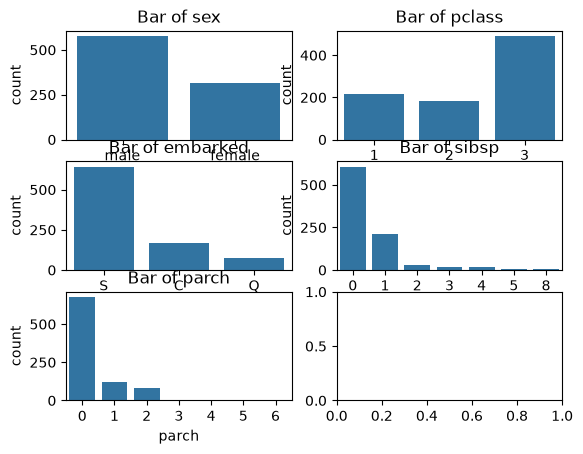

In [451]:


fig, axes = plt.subplots(3, 2)
sns.countplot(data=titanic, x="sex", ax=axes[0,0])
axes[0,0].set_title("Bar of sex")
sns.countplot(data=titanic, x="pclass", ax=axes[0,1])
axes[0,1].set_title("Bar of pclass")
sns.countplot(data=titanic, x="embarked", ax=axes[1,0])
axes[1,0].set_title("Bar of embarked")
sns.countplot(data=titanic, x="sibsp", ax=axes[1,1])
axes[1,1].set_title("Bar of sibsp")
sns.countplot(data=titanic, x="parch", ax=axes[2,0])
axes[2,0].set_title("Bar of parch")
plt.show()

In [452]:
resumen = (titanic.groupby("pclass")["survived"].mean())*100
print(resumen)

pclass
1    62.962963
2    47.282609
3    24.236253
Name: survived, dtype: float64


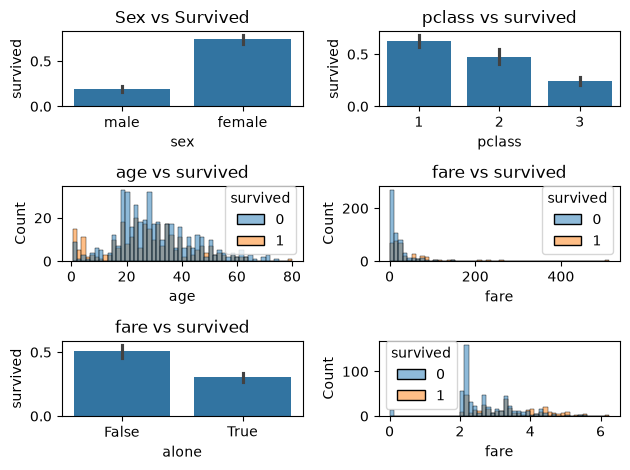

In [453]:
fig, axes = plt.subplots(3, 2)
sns.barplot(data=titanic, x="sex", y="survived", ax=axes[0,0])
axes[0,0].set_title("Sex vs Survived")
sns.barplot(data=titanic, x="pclass", y="survived" ,ax=axes[0,1])
axes[0,1].set_title("pclass vs survived")
sns.histplot(data=titanic, x="age", hue="survived",bins=50,ax=axes[1,0])
axes[1,0].set_title("age vs survived")
sns.histplot(data=titanic, x="fare", hue="survived",bins=50,ax=axes[1,1])
axes[1,1].set_title("fare vs survived")
sns.barplot(data=titanic, x="alone", y="survived",ax=axes[2,0])
axes[2,0].set_title("fare vs survived")
sns.histplot(data=titanic, x=np.log1p(titanic["fare"]),hue="survived",bins=50,ax=axes[2,1])
plt.tight_layout()
plt.show()

pclass  embarked
1       S           127
        C            85
        Q             2
2       S           164
        C            17
        Q             3
3       S           353
        Q            72
        C            66
Name: count, dtype: int64


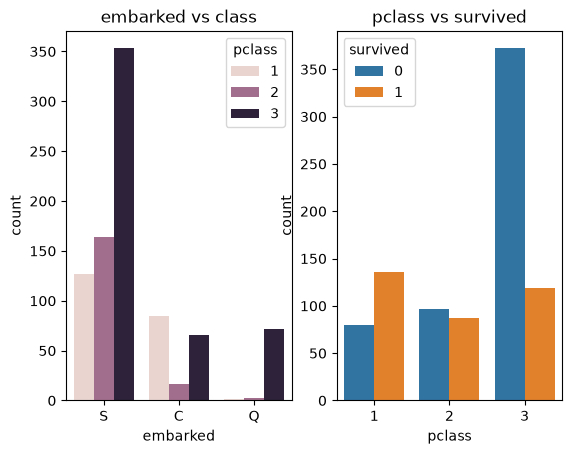

In [454]:
print(titanic.groupby("pclass")["embarked"].value_counts())

fig,ax = plt.subplots(1,2)
#sns.barplot(titanic,y="pclass",x="embarked",ax=ax[0])
sns.countplot(x=titanic["embarked"],hue=titanic["pclass"],ax=ax[0])
ax[0].set_title("embarked vs class")
sns.countplot(x=titanic["pclass"],hue=titanic["survived"],ax=ax[1])
ax[1].set_title("pclass vs survived")
plt.show()

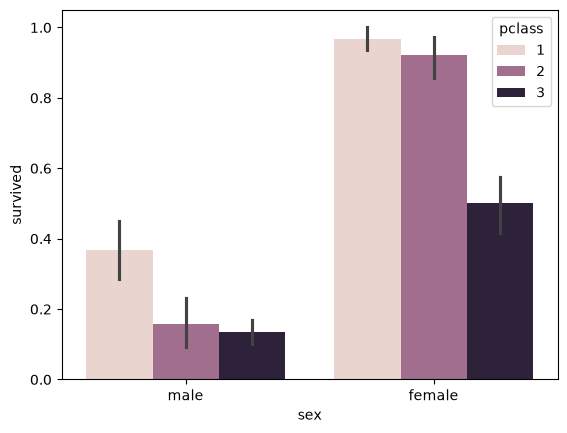

In [455]:
fig, ax = plt.subplots()
sns.barplot(titanic,x="sex",y="survived",hue="pclass",ax=ax)
plt.show()

In [456]:
titanic_copy = titanic.copy()
titanic_copy.head()
#Embarked y embark_town son las mismas columnas
#adult_male esta de mas, no aporta informacion nueva
#alive tambien es una categoria repetiva, tenemos a survived
#pclass y clase tambien son las mismas columnas
#alone esta demas debido a la informacion proporcionada de las columnas sibsp, parch
titanic_copy = titanic_copy.drop(columns=["embark_town","adult_male","class","alive","alone"])
print(f"total de filas duplicadas: {titanic_copy.duplicated().sum()}")
titanic_copy[titanic_copy.duplicated()].head(10)
titanic_copy = titanic_copy.drop_duplicates()
print(f"total de filas duplicadas: {titanic_copy.duplicated().sum()}")
titanic_copy.head()

total de filas duplicadas: 107
total de filas duplicadas: 0


,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,deck
0,0,3,male,22.0,1,0,7.2500,S,man,NaN
1,1,1,female,38.0,1,0,71.2833,C,woman,C
2,1,3,female,26.0,0,0,7.9250,S,woman,NaN
3,1,1,female,35.0,1,0,53.1000,S,woman,C
4,0,3,male,35.0,0,0,8.0500,S,man,NaN


In [457]:
#print(titanic.groupby(["pclass","embarked"])["deck"].value_counts())
titanic_copy.sort_values("fare",ascending=True).head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,deck
597,0,3,male,49.0,0,0,0.0,S,man,NaN
822,0,1,male,38.0,0,0,0.0,S,man,NaN
815,0,1,male,NaN,0,0,0.0,S,man,B
806,0,1,male,39.0,0,0,0.0,S,man,A
302,0,3,male,19.0,0,0,0.0,S,man,NaN


In [458]:
#titanic_copy.info()
print("\n")
print(f"Porcentaje de datos faltantes de la columna 'age': {((titanic_copy["age"].isna().sum()/784)*100).round(2)}%")
print(f"Porcentaje de datos faltantes de la columna 'deck': {((titanic_copy["deck"].isna().sum()/784)*100).round(2)}%")
print(f"Porcentaje de datos faltantes de la columna 'embarked': {((titanic_copy["embarked"].isna().sum()/784)*100).round(2)}%")

#Para age sera mediante la mediana de cada grupo, en este caso la mediana de mujer, la mediana de hombre
#la mediana de niña y la mediana de niño
titanic_copy.groupby(["sex","who"])["age"].mean()
titanic_copy["age"] = titanic_copy["age"].fillna(titanic_copy.groupby(["sex","who"])["age"].transform("median"))
print(f"Llenado de datos: \nPorcentaje de datos faltantes de la columna 'age': {((titanic_copy["age"].isna().sum()/784)*100).round(2)}%")
#Para embarked, como es una columna con categorias se utilizara la moda
titanic_copy["embarked"] = titanic_copy["embarked"].fillna(titanic_copy["embarked"].mode()[0])
print(f"Porcentaje de datos faltantes de la columna 'embarked': {((titanic_copy["embarked"].isna().sum()/784)*100).round(2)}%\n")
#Para la columna deck, porque los datos estan muy dispersos como para tomar una decision clara.
#Se opta por eliminarla
titanic_copy =  titanic_copy.drop(columns=["deck"])
print(f"Datos faltanes: {titanic_copy.isna().sum()}")



Porcentaje de datos faltantes de la columna 'age': 13.52%
Porcentaje de datos faltantes de la columna 'deck': 74.23%
Porcentaje de datos faltantes de la columna 'embarked': 0.26%
Llenado de datos: 
Porcentaje de datos faltantes de la columna 'age': 0.0%
Porcentaje de datos faltantes de la columna 'embarked': 0.0%

Datos faltanes: survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
who         0
dtype: int64


In [459]:
#Utilizar el metodo dispercion con |Z|>3 para age, fare, sibsp, parch

z = (titanic_copy[["age","fare","sibsp","parch"]].mean())/titanic_copy[["age","fare","sibsp","parch"]].std()
print(f"Outliers por z-score: {(z.abs()>3).sum()}\n")

#Utilizando el metodo IQR
def limites_iqr(serie, k=1.5):
    """Devuelve los límites inferior y superior según la regla del IQR."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

inf,sup = limites_iqr(titanic_copy["fare"])
print(f"Rangos aceptables: [{inf:,.0f},{sup:,.0f}]")
Outliers_iqr = titanic_copy[(titanic_copy["fare"]<inf) | (titanic_copy["fare"])>sup]
print("Outliers por IQR de fare:", len(Outliers_iqr))

inf,sup = limites_iqr(titanic_copy["age"])
print(f"Rangos aceptables: [{inf:,.0f},{sup:,.0f}]")
Outliers_iqr = titanic_copy[(titanic_copy["age"]<inf) | (titanic_copy["age"])>sup]
print("Outliers por IQR de age:", len(Outliers_iqr))

inf,sup = limites_iqr(titanic_copy["sibsp"])
print(f"Rangos aceptables: [{inf:,.0f},{sup:,.0f}]")
Outliers_iqr = titanic_copy[(titanic_copy["sibsp"]<inf) | (titanic_copy["sibsp"])>sup]
print("Outliers por IQR de sibsp:", len(Outliers_iqr))

inf,sup = limites_iqr(titanic_copy["parch"])
print(f"Rangos aceptables: [{inf:,.0f},{sup:,.0f}]")
Outliers_iqr = titanic_copy[(titanic_copy["parch"]<inf) | (titanic_copy["parch"])>sup]
print("Outliers por IQR de parch:", len(Outliers_iqr))

Outliers por z-score: 0

Rangos aceptables: [-31,73]
Outliers por IQR de fare: 0
Rangos aceptables: [1,57]
Outliers por IQR de age: 0
Rangos aceptables: [-2,2]
Outliers por IQR de sibsp: 0
Rangos aceptables: [-2,2]
Outliers por IQR de parch: 0


In [460]:
#La mayoria parece que esta dentro del rango pero hay cosas que no llegan a tener mucho sentido
titanic_copy["age"].sort_values(ascending=True) #Edades menores a 1 años?
error_edad = titanic_copy["age"] < 1
print(f"Errores de edad: {error_edad.sum()}")

titanic_copy["fare"].sort_values(ascending=True) #arriba de 500 libras?
error_fare = (titanic_copy["fare"] > 500) | (titanic_copy["fare"] <= 0)
print(f"Error del precio del boleto: {error_fare.sum()}")

#Para comprobar las columnas sibsp y parch, se ocupara la columna alone
#error_sibsp_parch = titanic_copy[(titanic_copy["sibsp"] > 0) & (titanic_copy["parch"] > 0) & (titanic_copy["alone"] == 1)]
#print(f"Errores con inconsistencia: {error_sibsp_parch["alone"].sum()}")

titanic_copy["sibsp"].sort_values(ascending=True) #Tener 5 hermanos en un viaje?
error_hermanos = titanic_copy["sibsp"] >= 8
print(f"Errror de hermano: {error_hermanos.sum()}")

Errores de edad: 6
Error del precio del boleto: 13
Errror de hermano: 2


In [461]:
titanic_copy = titanic_copy[~error_edad] #Eliminamos los errores de edad
titanic_copy = titanic_copy[~error_fare] #Eliminamos el error de los boletos
titanic_copy = titanic_copy[~error_hermanos] #Eliminamos el error con los hermanos

titanic_copy.sort_values("age",ascending=True)

C:\Users\flavs\AppData\Local\Temp\ipykernel_10428\1751653729.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  titanic_copy = titanic_copy[~error_fare] #Eliminamos el error de los boletos
C:\Users\flavs\AppData\Local\Temp\ipykernel_10428\1751653729.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  titanic_copy = titanic_copy[~error_hermanos] #Eliminamos el error con los hermanos


,survived,pclass,sex,age,sibsp,parch,fare,embarked,who
381,1,3,female,1.0,0,2,15.7417,C,child
386,0,3,male,1.0,5,2,46.9000,S,child
788,1,3,male,1.0,1,2,20.5750,S,child
827,1,2,male,1.0,0,2,37.0042,C,child
164,0,3,male,1.0,4,1,39.6875,S,child
...,...,...,...,...,...,...,...,...,...
116,0,3,male,70.5,0,0,7.7500,Q,man
96,0,1,male,71.0,0,0,34.6542,C,man
493,0,1,male,71.0,0,0,49.5042,C,man
851,0,3,male,74.0,0,0,7.7750,S,man


In [462]:
titanic_copy.describe()

,survived,pclass,age,sibsp,parch,fare
count,763.000000,763.000000,763.000000,763.000000,763.000000,763.000000
mean,0.410223,2.251638,30.131062,0.509830,0.410223,33.153789
std,0.492197,0.852421,13.628093,0.918372,0.837601,43.082319
min,0.000000,1.000000,1.000000,0.000000,0.000000,4.012500
25%,0.000000,1.000000,22.000000,0.000000,0.000000,8.050000
50%,0.000000,3.000000,30.000000,0.000000,0.000000,16.000000
75%,1.000000,3.000000,36.000000,1.000000,1.000000,33.760400
max,1.000000,3.000000,80.000000,5.000000,6.000000,263.000000


In [463]:
titanic.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [464]:
titanic_copy.info()
titanic.info()

<class 'pandas.DataFrame'>
Index: 763 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  763 non-null    int64  
 1   pclass    763 non-null    int64  
 2   sex       763 non-null    str    
 3   age       763 non-null    float64
 4   sibsp     763 non-null    int64  
 5   parch     763 non-null    int64  
 6   fare      763 non-null    float64
 7   embarked  763 non-null    str    
 8   who       763 non-null    str    
dtypes: float64(2), int64(4), str(3)
memory usage: 59.6 KB
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    in

In [465]:
#nuevas columnas
#fsize => family size = sibsp + parch
#u_fare => precio por persona
#r_age => 15 < child, 15 >= adult < 50, 50>= eldery
#fare_% => 

titanic_copy["fsize"] =  titanic_copy["sibsp"] + titanic_copy["parch"]
titanic_copy["u_fare"] = titanic_copy["fare"]/(titanic_copy["fsize"]+1)
titanic_copy["r_age"] = pd.cut(titanic_copy["age"],bins=[0,15,50,np.inf],labels=["child","adult","eldery"])

#print(titanic_copy.groupby(["pclass","embarked","r_age"])["fare"].median())
#grupo_media=titanic_copy.groupby(["pclass","embarked","r_age"])["fare"].transform("median")

#titanic_copy["spendq"] = ((titanic_copy["fare"]-grupo_media)/grupo_media)*100

titanic_copy
titanic_copy.head(10)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,fsize,u_fare,r_age
0,0,3,male,22.0,1,0,7.2500,S,man,1,3.62500,adult
1,1,1,female,38.0,1,0,71.2833,C,woman,1,35.64165,adult
2,1,3,female,26.0,0,0,7.9250,S,woman,0,7.92500,adult
3,1,1,female,35.0,1,0,53.1000,S,woman,1,26.55000,adult
4,0,3,male,35.0,0,0,8.0500,S,man,0,8.05000,adult
5,0,3,male,31.0,0,0,8.4583,Q,man,0,8.45830,adult
6,0,1,male,54.0,0,0,51.8625,S,man,0,51.86250,eldery
7,0,3,male,2.0,3,1,21.0750,S,child,4,4.21500,child
8,1,3,female,27.0,0,2,11.1333,S,woman,2,3.71110,adult
9,1,2,female,14.0,1,0,30.0708,C,child,1,15.03540,child


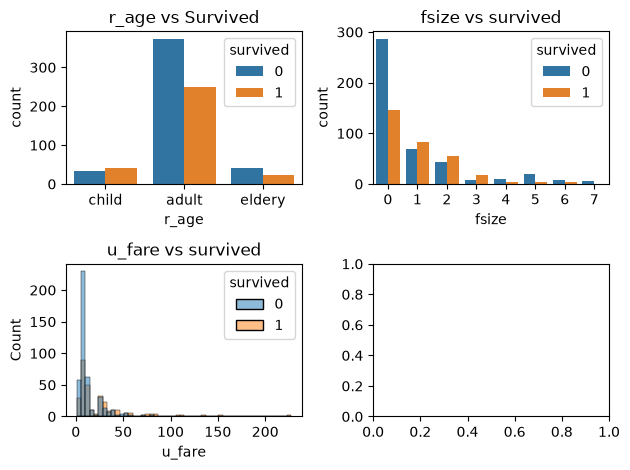

In [466]:
fig, axes = plt.subplots(2, 2)
sns.countplot(data=titanic_copy, x="r_age", hue="survived", ax=axes[0,0])
axes[0,0].set_title("r_age vs Survived")
sns.countplot(data=titanic_copy, x="fsize", hue="survived",ax=axes[0,1])
axes[0,1].set_title("fsize vs survived")
sns.histplot(data=titanic_copy, x="u_fare", hue="survived",bins=50,ax=axes[1,0])
axes[1,0].set_title("u_fare vs survived")
#sns.histplot(data=titanic_copy, x="spendq", hue="survived",bins=50,ax=axes[1,1])
#axes[1,1].set_title("spendq vs survived")
plt.tight_layout()
plt.show()

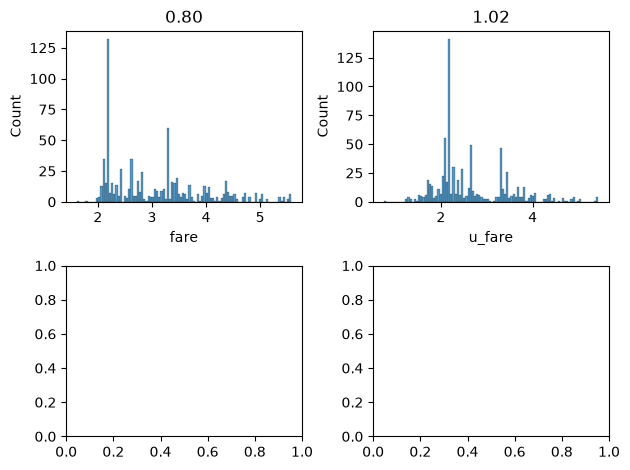

In [467]:
fig, axes = plt.subplots(2, 2)
sns.histplot( x=np.log1p(titanic_copy["fare"]),bins=100, ax=axes[0,0])
axes[0,0].set_title(f"{np.log1p(titanic_copy["fare"]).skew():.2f}")
sns.histplot(x=np.log1p(titanic_copy["u_fare"]),bins=100,ax=axes[0,1])
axes[0,1].set_title(f"{np.log1p(titanic_copy["u_fare"]).skew():.2f}")
#sns.histplot(x=np.log1p(titanic_copy["spendq"]),bins=100,ax=axes[1,0])
#axes[1,0].set_title(f"{np.log1p(titanic_copy["spendq"]).skew():.2f}")
plt.tight_layout()
plt.show()

In [ ]:
#Codificación
#survived -> binaria
#pclass -> normalizado
#sex -> binaria
#age -> normalizado
#sibs -> normalizado
#pads -> normalizado
#fare ->logaritmo -> normalizado
#embarked -> getdummies with drop = 'first'
#who -> getdummies with drop = 'first'
#fsize -> normalizado
#u_fare -> logaritmo -> normalizado
#r_age -> OrdinalEncoder
#spendq -> logaritmo -> normalizado

titanic_s_copy = titanic_copy.copy() 

pd.get_dummies(titanic_copy["embarked"],prefix="embarked",drop_first=True,dtype=int)
pd.get_dummies(titanic_copy["who"],prefix="who",drop_first=True,dtype=int)
titanic_copy["fare"] = np.log1p(titanic_copy[["fare"]])
titanic_copy["u_fare"] = np.log1p(titanic_copy[["u_fare"]])
OrdinalEncoder(categories=[["child", "adult", "eldery"]]).fit(titanic_copy[["r_age"]]).categories_
titanic_copy.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,fsize,u_fare,r_age
0,0,3,male,22.0,1,0,2.110213,S,man,1,1.531476,adult
1,1,1,female,38.0,1,0,4.280593,C,woman,1,3.601186,adult
2,1,3,female,26.0,0,0,2.188856,S,woman,0,2.188856,adult
3,1,1,female,35.0,1,0,3.990834,S,woman,1,3.316003,adult
4,0,3,male,35.0,0,0,2.202765,S,man,0,2.202765,adult


In [470]:
X = titanic_copy.drop(columns="survived")   
y = titanic_copy["survived"]                                       

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (610, 11) | Test: (153, 11)


In [ ]:
escalador = MinMaxScaler()
escalador.fit(X_train[["pclass","age","sibsp","parch","fare","fsize","u_fare"]])


,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](7,)","[ 3. ,80. , 5. ,..., 5.58, 7. , 5.43]"
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](7,)","[1. ,1. ,0. ,...,1.61,0. ,1.23]"
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](7,)","[ 2. ,79. , 5. ,..., 3.96, 7. , 4.21]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['pclass','age','sibsp',...,'fare','fsize','u_fare']"
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](7,)","[-0.5 ,-0.01, 0. ,...,-0.41, 0. ,-0.29]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,610


In [472]:
numericas = ["pclass","age","sibsp","parch","fsize"]
asimetricas = ["fare", "u_fare"]
nominales = ["survived", "sex",]
ordinales = ["r_age"]

pipeline_asimetrico = Pipeline([
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("escalar", StandardScaler()),
])

preprocesador = ColumnTransformer([
    ("num", StandardScaler(), numericas),
    ("asim", pipeline_asimetrico, asimetricas),
    ("nom", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False), nominales),   # garaje: una sola columna
    ("ord", OrdinalEncoder(categories=[["a reformar", "buen estado", "como nuevo"]]), ordinales),
])
preprocesador

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('asim', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_